# Individual JADES flow posteriors

In [10]:
import os, sys, re
from pathlib import Path
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "encoder_fusion/model/fusion.py").is_file())
FLOW_DIR = ROOT / "flow"
os.chdir(FLOW_DIR)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "neurips"))
from flow.model.flow import Flow
from flow.data.datamodule_jades import JADESDataModule
from plotstyle import C_IMAGE, C_SPECTRUM, C_RED_BRIGHT, C_ORIG, use_style, style_axes, fs

CONFIG = Path("z_1_3.yaml")  # change to Path("full.yaml") for no redshift-range cut
SEEDS = [0, 1, 2]           # use [0] for one flow
N_POST = 3000
rerun = False  # set True to retrain flows and overwrite checkpoints
cfg = yaml.safe_load(CONFIG.read_text())
base_name = cfg["trainer"]["logger"]["init_args"]["name"]
use_style(1.2)


## 1. Train from the notebook



In [11]:
if rerun:
    for seed in SEEDS:
        run_name = f"{base_name}_seed{seed}"
        !{sys.executable} model/flow.py fit --config {CONFIG} --seed_everything={seed} --trainer.logger.init_args.name={run_name}
else:
    print("Skipping training; rerun = False. Set rerun = True to retrain flows and overwrite checkpoints.")

Skipping training; rerun = False. Set rerun = True to retrain flows and overwrite checkpoints.


## 2. Load the best checkpoints and sample the test galaxies

The DataModule recomputes the frozen CLIP latents in batches; it does not train the fusion model.
The same data preparation is used for training and analysis. Labels and sample dimensions are aligned
with `data.rows`, `data.dja_ids` and `data.jades_ids`.


In [12]:
models, checkpoints = [], []
log_root = Path(cfg["trainer"]["logger"]["init_args"]["save_dir"])
for seed in SEEDS:
    versions = list((log_root / f"{base_name}_seed{seed}").glob("version_*"))
    if not versions:
        raise FileNotFoundError(f"No training run found for seed {seed}. Run the training cell first.")
    latest = max(versions, key=lambda p: int(p.name.split("_")[-1]))
    paths = list((latest / "checkpoints").glob("*.ckpt"))
    if len(paths) != 1:
        raise RuntimeError(f"Expected one best checkpoint in {latest}, found {len(paths)}")
    checkpoints.append(paths[0])
    models.append(Flow.load_from_checkpoint(paths[0], map_location="cpu").eval())
print("Best checkpoints:", *checkpoints, sep="\n")

# Use the saved data settings, including the exact fusion checkpoint used in training.
data_config = dict(models[0].hparams.data_config)
assert all(dict(m.hparams.data_config) == data_config for m in models)
data = JADESDataModule(**data_config)
data.setup("fit")
te = data.te
X_test = data.X[te]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Draw from the equal-weight mixture; the total is exactly N_POST.
n_per_flow = np.random.multinomial(N_POST, np.full(len(models), 1 / len(models)))
post_model = torch.cat([m.to(DEVICE).sample(X_test, n=int(n))
                        for m, n in zip(models, n_per_flow) if n], dim=0).numpy()
print("Posterior:", post_model.shape)


Best checkpoints:
outputs/flow_jades_z_1_3_seed0/version_0/checkpoints/epoch=10-val_nll=2.9467.ckpt
outputs/flow_jades_z_1_3_seed1/version_0/checkpoints/epoch=18-val_nll=3.0324.ckpt
outputs/flow_jades_z_1_3_seed2/version_0/checkpoints/epoch=12-val_nll=3.0655.ckpt
Converting flux from f_nu (uJy) to f_lambda (∝ f_nu / λ²) (use_jansky=True to disable this conversion)
grade in (1, 2, 3) filtering: 26486/42196 samples kept
valid_pix_frac > 0.5 filtering: 25025/42196 samples kept
LowResDataset: 25025 spectra, 56 pixels (1.004–1.991 µm)
Frozen fusion: /nexus/posix0/MIA-astro-env/ivemo/yacheng/ssl_outthere/encoder_fusion/outputs/fusion_dja_image_attn_spectrum_attn/version_2/checkpoints/epoch=39-R10=0.158-val_loss=4.7346.ckpt (cuda)
Flow data: 1189 spectra -> 1047 unique JADES galaxies; train 523 / val 262 / test 262
Posterior: (3000, 262, 5)


In [13]:
# Samples already have standardization undone by Flow.sample().
# These are still model-label coordinates; convert log10(1+z) to z for plots only.
post = post_model.copy()
yt, yt16, yt84 = (a[te].copy() for a in (data.Y, data.Y16, data.Y84))
names = list(data.hparams.target_columns)
plot_labels = {
    "log1pz": r"$z$", "logmass": r"$\log M_\star$",
    "logsfr100": r"$\log \mathrm{SFR}_{100}$", "gas_logz": r"$\log Z_{\rm gas}/Z_\odot$",
    "av": r"$\log_{10}(A_V/\mathrm{mag})$",
}
LABELS = [plot_labels.get(name, name) for name in names]
D = len(names)
if "log1pz" in names:
    z_index = names.index("log1pz")
    for a in (post[..., z_index], yt[:, z_index], yt16[:, z_index], yt84[:, z_index]):
        a[:] = 10 ** a - 1
lo16, med, hi84 = np.percentile(post, [16, 50, 84], axis=0)


def nmad(e):
    return 1.4826 * np.median(np.abs(e - np.median(e)))


def err(p, t, d):
    return (p - t) / (1 + t) if names[d] == "log1pz" else p - t


## 3. Spectra and example selection


In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from astropy.io import fits
from astropy.table import Table
from scipy.ndimage import gaussian_filter
from plotstyle import IMAGE_ROOT, DJA_FITS, XMATCH, scalebar

z_index, mass_index = names.index("log1pz"), names.index("logmass")
test_rows = data.rows[te]
did_all = data.dja_ids[te]
surv_te = data.surveys[te]
EX_ZBINS = [1.0, 1.5, 2.0, 2.5, 3.0]  # editable even when CONFIG = full.yaml


In [15]:
xt = Table.read(XMATCH)
with fits.open(DJA_FITS, memmap=True) as hdul:
    WAVE = np.asarray(hdul["WAVE"].data, dtype=np.float32)
    cat = hdul["CATALOG"].data
    FLUX  = {i: np.asarray(cat["flux"][i], np.float32) for i in did_all}
    VALID = {i: np.asarray(cat["valid_spec"][i], bool) for i in did_all}
    SN50  = {i: float(cat["sn50"][i]) for i in did_all}

EMISSION_LINES = {r"Ly$\alpha$": 0.1216, "[OII]": 0.3727, r"H$\beta$": 0.4861, "[OIII]": 0.5007,
                  r"H$\alpha$": 0.6563, "[SIII]": 0.9531, r"Pa$\gamma$": 1.0938, r"Pa$\beta$": 1.2822}


In [16]:
# one galaxy per redshift bin: S/N50 > 10, log M posterior width closest to the bin median
sn_all = np.array([SN50[i] for i in did_all])
sig_m = (hi84[:, mass_index] - lo16[:, mass_index]) / 2
EX = []
for zlo, zhi in zip(EX_ZBINS[:-1], EX_ZBINS[1:]):
    m = np.where((yt[:, z_index] > zlo) & (yt[:, z_index] <= zhi) & (sn_all > 10))[0]
    if len(m):
        EX.append(m[np.argmin(np.abs(sig_m[m] - np.median(sig_m[m])))])


print("Example test indices:", EX)
print("Example DJA IDs:", did_all[EX].tolist())


Example test indices: [138, 115, 196, 177]
Example DJA IDs: [21470, 27546, 20090, 24193]


## 4. Individual posterior plotting helpers


In [17]:
def load_cutout(r, half=32):
    img = np.load(IMAGE_ROOT / str(xt["rel_path"][r]), mmap_mode="r")[int(xt["local_idx"][r])]
    img = np.nan_to_num(np.asarray(img, dtype=np.float32))
    c = img.shape[0] // 2
    return img[c - half:c + half, c - half:c + half]


def hpd_levels(H, probs):
    # density thresholds enclosing the given probability mass
    h = np.sort(H.ravel())[::-1]
    cdf = np.cumsum(h) / h.sum()
    return [h[min(np.searchsorted(cdf, p), len(h) - 1)] for p in probs]


def corner(axes, s, truth, tlo, thi, color=C_IMAGE):
    rng_ = [np.percentile(np.r_[s[:, i], [truth[i]] * 10], [0.5, 99.5]) for i in range(D)]
    rng_ = [(a - 0.08 * (b - a), b + 0.08 * (b - a)) for a, b in rng_]
    for i in range(D):
        for j in range(D):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            if i == j:
                ax.axvspan(tlo[i], thi[i], color=C_RED_BRIGHT, alpha=0.15, lw=0)
                ax.hist(s[:, i], bins=40, range=rng_[i], density=True, histtype="stepfilled",
                        color=color, alpha=0.35)
                ax.hist(s[:, i], bins=40, range=rng_[i], density=True, histtype="step", color=color)
                q16, q50, q84 = np.percentile(s[:, i], [16, 50, 84])
                for q in (q16, q50, q84):
                    ax.axvline(q, color=color, ls="--", lw=1)
                ax.axvline(truth[i], color=C_RED_BRIGHT, lw=1.6)
                ax.text(0.5, 1.30, rf"${q50:.2f}^{{+{q84 - q50:.2f}}}_{{-{q50 - q16:.2f}}}$",
                        transform=ax.transAxes, ha="center", va="bottom", color=color, fontsize=fs(9))
                ax.text(0.5, 1.04, rf"${truth[i]:.2f}^{{+{thi[i] - truth[i]:.2f}}}_{{-{truth[i] - tlo[i]:.2f}}}$",
                        transform=ax.transAxes, ha="center", va="bottom", color=C_RED_BRIGHT, fontsize=fs(9))
                ax.set_yticks([])
                ax.set_xlim(rng_[i])
            else:
                H, xe, ye = np.histogram2d(s[:, j], s[:, i], bins=30, range=[rng_[j], rng_[i]])
                H = gaussian_filter(H, 1.0)
                l95, l68 = hpd_levels(H, [0.95, 0.68])
                xc, yc = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
                ax.contourf(xc, yc, H.T, levels=[l95, l68, H.max() * 1.001], colors=[color, color], alpha=0.25)
                ax.contour(xc, yc, H.T, levels=[l95, l68], colors=color, linewidths=1)
                ax.axvline(truth[j], color=C_RED_BRIGHT, lw=1)
                ax.axhline(truth[i], color=C_RED_BRIGHT, lw=1)
                ax.plot(truth[j], truth[i], "s", color=C_RED_BRIGHT, ms=4)
                ax.set_xlim(rng_[j]); ax.set_ylim(rng_[i])
            ax.tick_params(direction="in", labelsize=fs(8))
            if i < D - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(LABELS[j], fontsize=fs(10))
            if j > 0 or i == 0:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel(LABELS[i], fontsize=fs(10))
    handles = [Patch(facecolor=color, edgecolor=color, alpha=0.35, label="flow posterior (68/95%)"),
               Line2D([], [], color=color, ls="--", lw=1, label="posterior 16/50/84%"),
               Line2D([], [], color=C_RED_BRIGHT, lw=1.6, marker="s", ms=5, label="catalog p50"),
               Patch(facecolor=C_RED_BRIGHT, alpha=0.15, label="catalog 16–84%")]
    axes[0, D - 1].legend(handles=handles, loc="upper right", frameon=False, fontsize=fs(11))


def plot_example(k):
    r, did, zs = test_rows[k], int(did_all[k]), yt[k, z_index]
    fig = plt.figure(figsize=(15, 7.6))
    outer = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.15)
    cgs = outer[0].subgridspec(D, D, hspace=0.08, wspace=0.08)
    axes = np.array([[fig.add_subplot(cgs[i, j]) for j in range(D)] for i in range(D)])
    corner(axes, post[:, k], yt[k], yt16[k], yt84[k])
    # image cutout and spectrum
    rgs = outer[1].subgridspec(2, 1, height_ratios=[1.15, 1], hspace=0.28)
    ax0 = fig.add_subplot(rgs[0])
    img = load_cutout(r)
    lo, hi = np.percentile(img, [1, 99.7])
    ax0.imshow(np.arcsinh(np.clip((img - lo) / (hi - lo), 0, None) * 10), cmap="gray", origin="lower")
    ax0.set_xticks([]); ax0.set_yticks([])
    ax0.text(0.03, 0.97, f"{surv_te[k]}  DJA {did}\n" + rf"$z_{{\rm spec}}$={zs:.3f}   S/N$_{{50}}$={SN50[did]:.0f}",
             transform=ax0.transAxes, color=C_RED_BRIGHT, fontsize=fs(11), fontweight="bold", va="top", ha="left")
    scalebar(ax0, n_pix=20, fontsize=fs(10))

    ax1 = fig.add_subplot(rgs[1])
    ok = VALID[did] & np.isfinite(FLUX[did])
    ax1.step(WAVE[ok], FLUX[did][ok], where="mid", color=C_SPECTRUM, lw=1.1)
    ax1.axvspan(1.0, 2.0, color=C_ORIG, alpha=0.15, lw=0)
    f_lo, f_hi = np.percentile(FLUX[did][ok], [0.5, 99.5])
    ylo, yhi = f_lo - 0.1 * (f_hi - f_lo), f_hi + 0.35 * (f_hi - f_lo)
    ax1.set_ylim(ylo, yhi)
    for name, wl in EMISSION_LINES.items():
        wo = wl * (1 + zs)
        if WAVE[ok].min() < wo < WAVE[ok].max():
            ax1.axvline(wo, color="0.45", lw=0.8, ls=":")
            ax1.text(wo, yhi, name, rotation=90, va="top", ha="right", fontsize=fs(8), color="0.3")
    ax1.set(xlabel=r"$\lambda_{\rm obs}$ [$\mu$m]", ylabel=r"$f_\nu$ [$\mu$Jy]")
    style_axes(ax1)
    plt.show()


## 5. Plot examples

Call `plot_example(k)` for any test-set index, or adjust `EX` above.


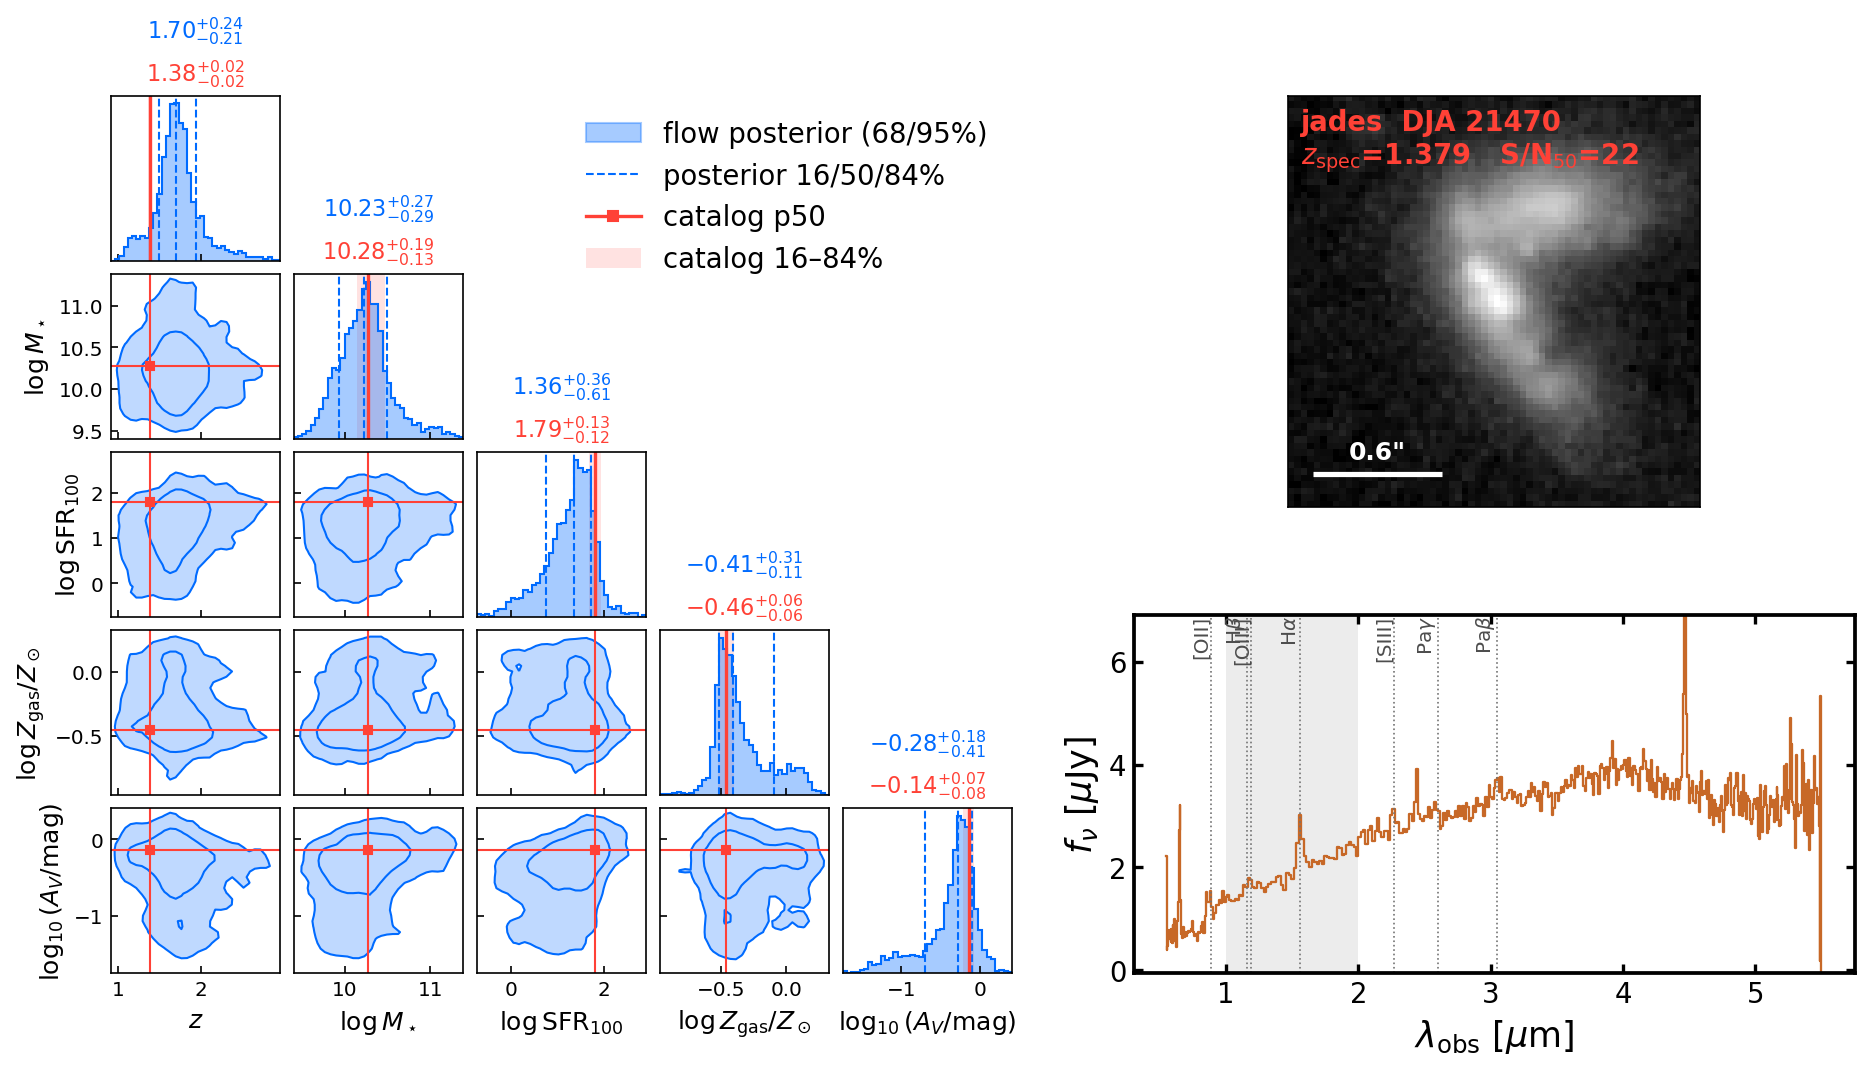

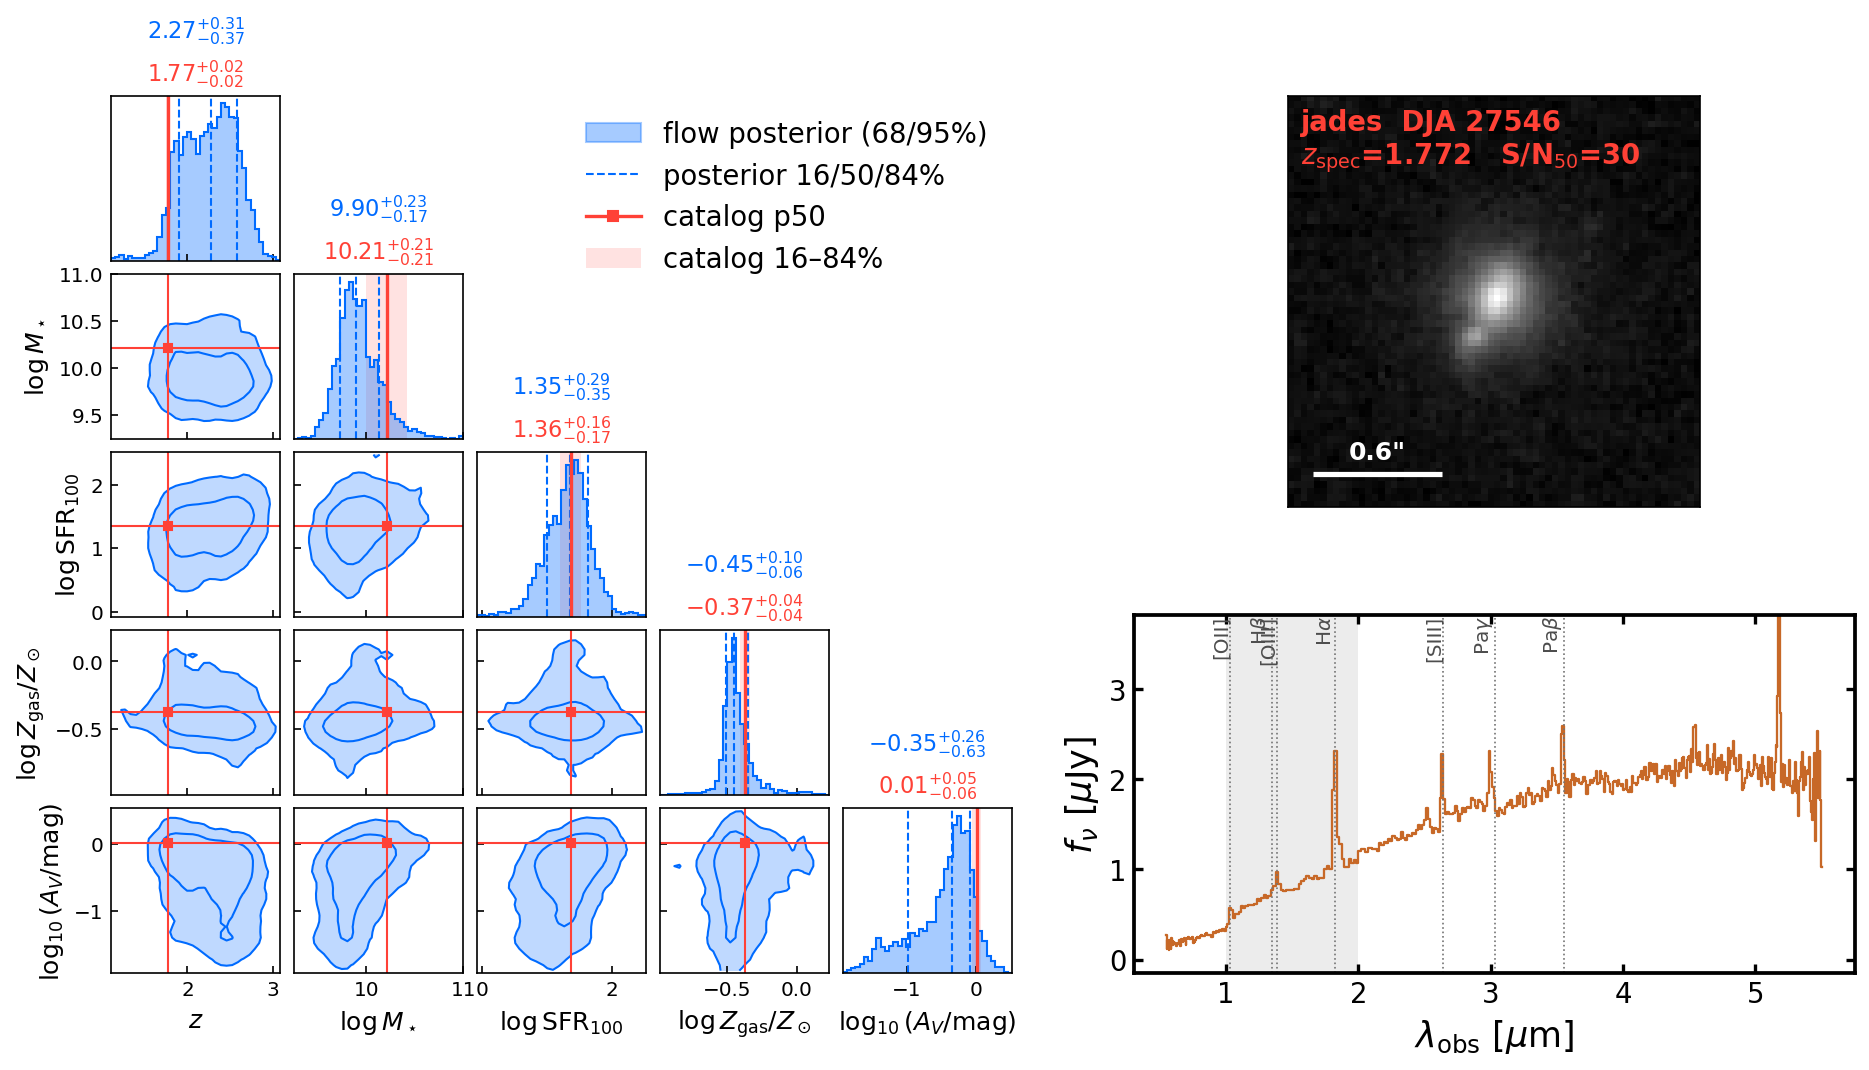

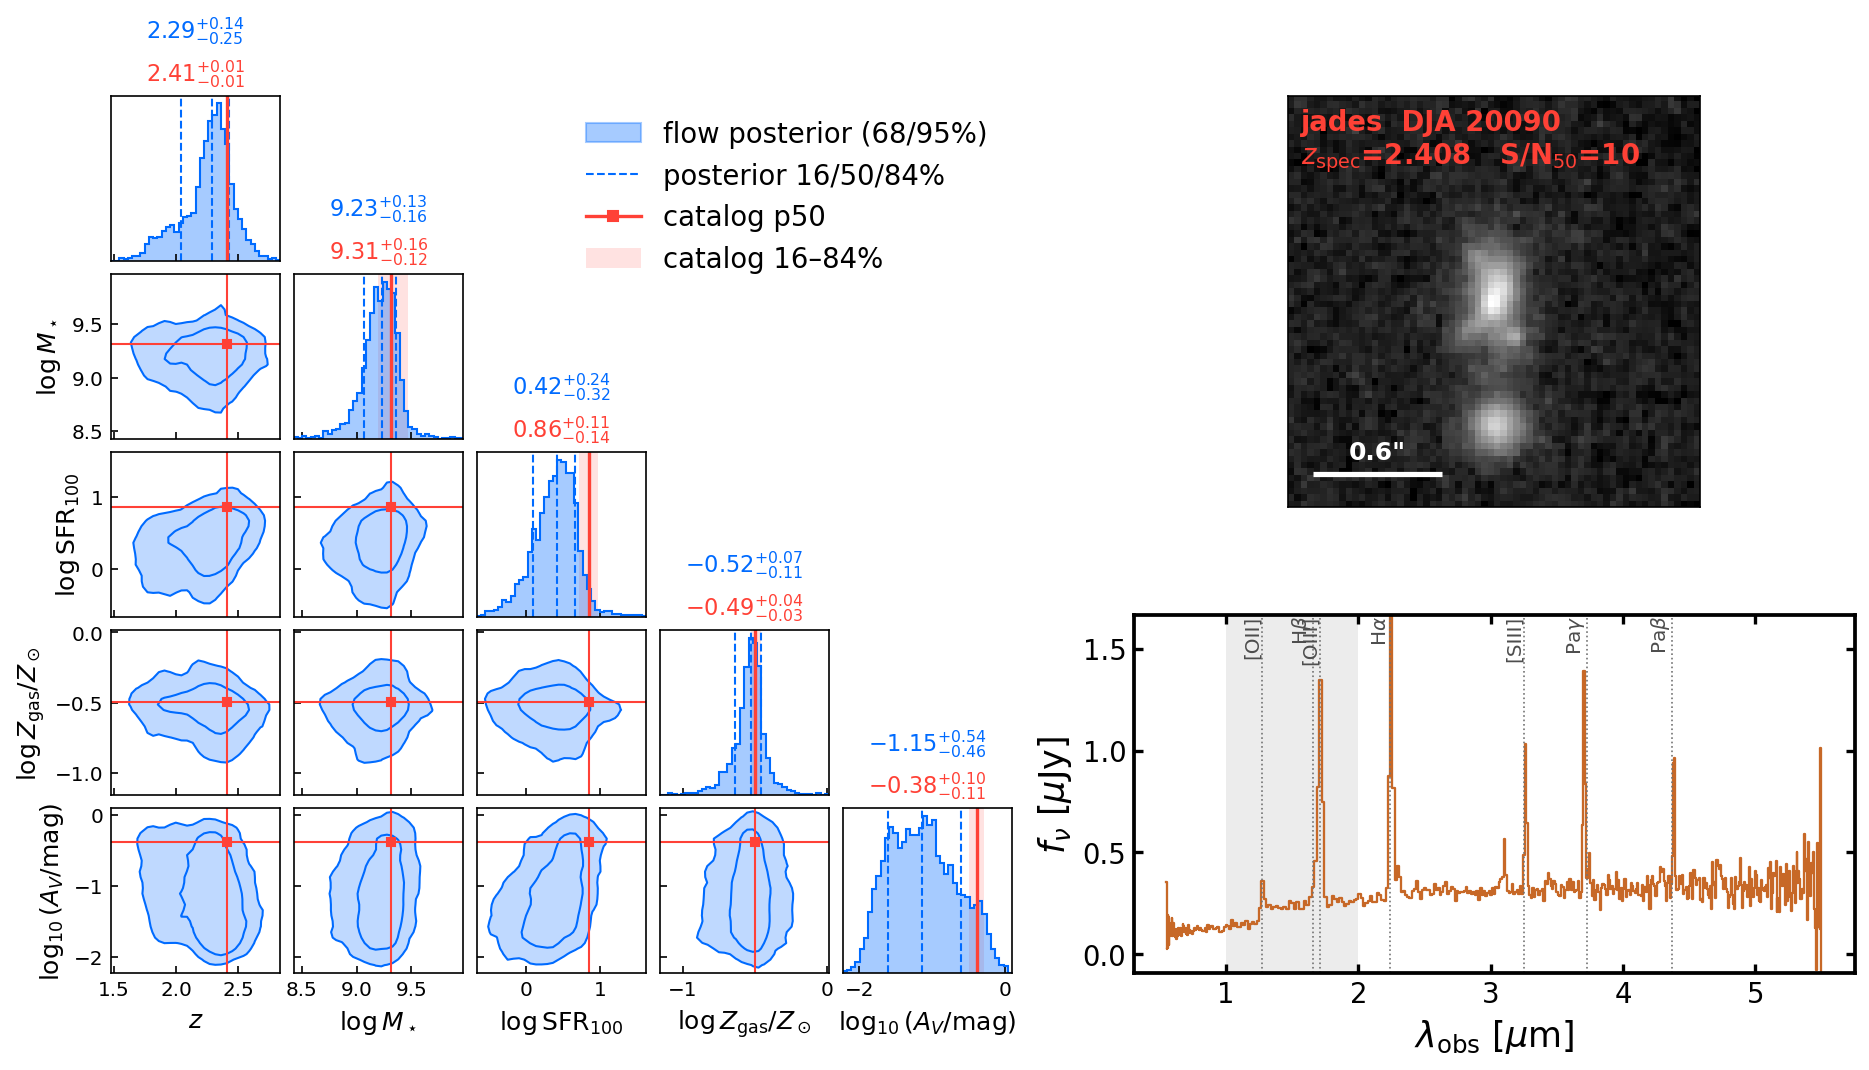

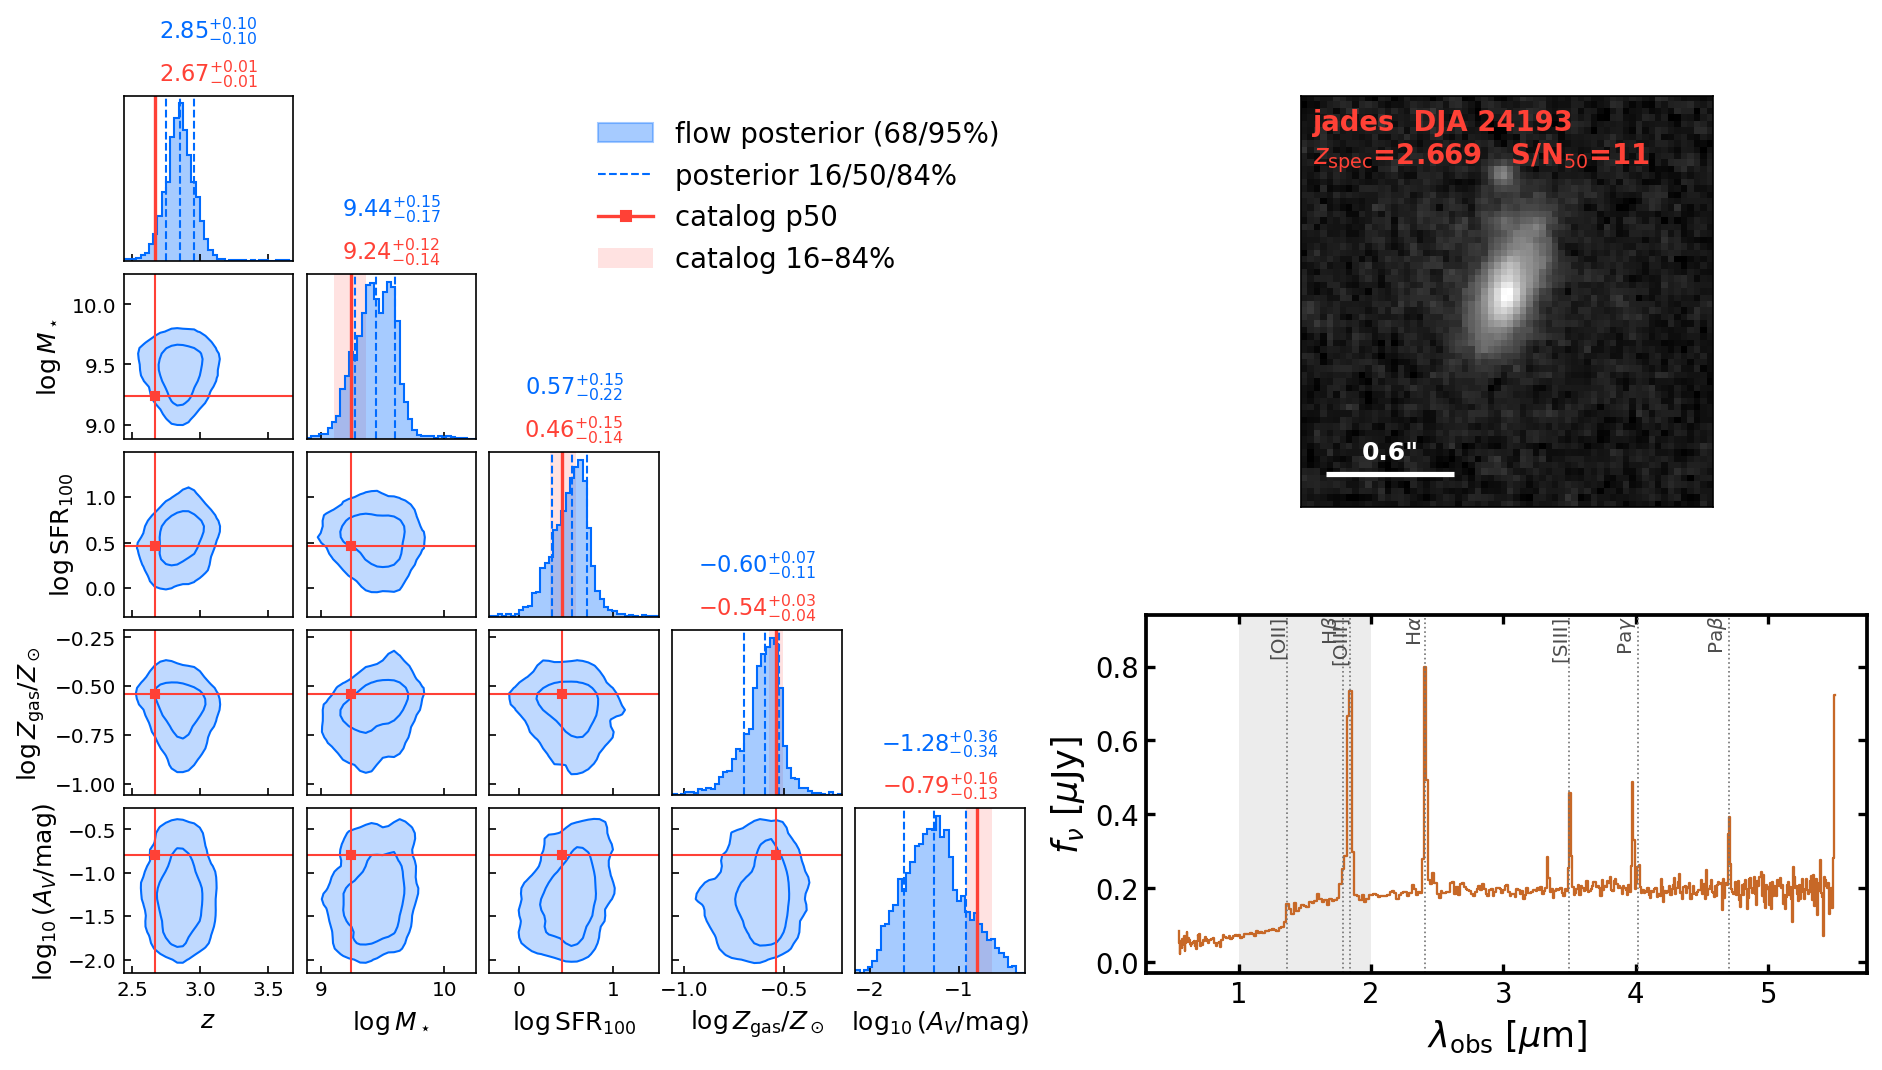

In [18]:
for k in EX:
    plot_example(k)


In [29]:
# 6. Direct label-space grid: evaluate the full joint PDF, then marginalize.
# No new Gaussian samples are drawn. Existing samples only choose default bounds;
# set GRID_BOUNDS to a (D, 2) array in model-label units to choose the box yourself.
from scipy.special import logsumexp
from time import perf_counter

GRID_K = EX[0] if EX else 0  # test-set index of one galaxy
N_GRID = 20                 # 20**5 = 3.2 million joint-density evaluations per flow
GRID_BATCH_SIZE = 32768
GRID_BOUNDS = None          # log10(1+z), log mass, log SFR100, log Zgas, log A_V


@torch.no_grad()
def label_grid_posterior(k, n_grid=20, batch_size=32768, bounds=None):
    started = perf_counter()
    if bounds is None:
        lo, hi = np.percentile(post_model[:, k], [0.1, 99.9], axis=0)
        pad = 0.15 * (hi - lo)
        bounds = np.column_stack([lo - pad, hi + pad])
    edges = [np.linspace(lo, hi, n_grid + 1) for lo, hi in np.asarray(bounds)]
    centers = [(e[:-1] + e[1:]) / 2 for e in edges]
    print(f"Grid bounds in model-label units ({n_grid} bins, {n_grid + 1} edges per dimension):")
    for name, e in zip(names, edges):
        print(f"  {name:12s} [{e[0]:.6f}, {e[-1]:.6f}]  bin width = {e[1] - e[0]:.6f}")
        if name == "log1pz":
            ze = 10 ** e - 1
            print(f"    displayed z [{ze[0]:.6f}, {ze[-1]:.6f}]; "
                  f"z-bin widths = {np.diff(ze).min():.6f}–{np.diff(ze).max():.6f}")
    shape = (n_grid,) * len(centers)
    n_points = int(np.prod(shape))
    log_pdf = np.empty(n_points, dtype=np.float32)
    x = X_test[k:k + 1]
    for model in models:
        model.eval()
    print(f"Evaluating {n_points:,} label-grid points for galaxy {k}, {len(models)} flow(s)")
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        indices = np.unravel_index(np.arange(start, stop), shape)
        theta = np.column_stack([axis[ii] for axis, ii in zip(centers, indices)])
        # log_prob maps labels towards the Gaussian and includes both the flow
        # Jacobian and standardization Jacobian. Average ensemble DENSITIES.
        member_logp = np.stack([m.log_prob(x, theta).cpu().numpy() for m in models])
        log_pdf[start:stop] = logsumexp(member_logp, axis=0) - np.log(len(models))
    log_cell_volume = sum(np.log(e[1] - e[0]) for e in edges)
    log_box_mass = logsumexp(log_pdf.astype(np.float64)) + log_cell_volume
    mass = np.exp(log_pdf.astype(np.float64) + log_cell_volume - log_box_mass).reshape(shape)
    result = dict(k=k, edges=edges, centers=centers, log_density=log_pdf.reshape(shape),
                density=np.exp(log_pdf).reshape(shape), mass=mass,
                  box_mass=float(np.exp(log_box_mass)), n_grid=n_grid)
    result["elapsed_seconds"] = perf_counter() - started
    return result


grid_posterior = label_grid_posterior(GRID_K, N_GRID, GRID_BATCH_SIZE, GRID_BOUNDS)
print(f"Approximate probability in the grid box: {grid_posterior['box_mass']:.4f}")
print(f"Grid computation time (joint PDF + normalization): {grid_posterior['elapsed_seconds']:.2f} s")
# Plotted marginals are normalized within this finite box. Widen bounds/check
# a finer N_GRID if the estimated box probability is not close to one.


Grid bounds in model-label units (20 bins, 21 edges per dimension):
  log1pz       [0.218834, 0.658986]  bin width = 0.022008
    displayed z [0.655139, 3.560227]; z-bin widths = 0.086035–0.225329
  logmass      [9.100507, 11.717181]  bin width = 0.130834
  logsfr100    [-1.362308, 3.789318]  bin width = 0.257581
  gas_logz     [-1.476804, 0.543002]  bin width = 0.100990
  av           [-2.207260, 0.744313]  bin width = 0.147579
Evaluating 3,200,000 label-grid points for galaxy 138, 3 flow(s)
Approximate probability in the grid box: 0.9938
Grid computation time (joint PDF + normalization): 7.76 s


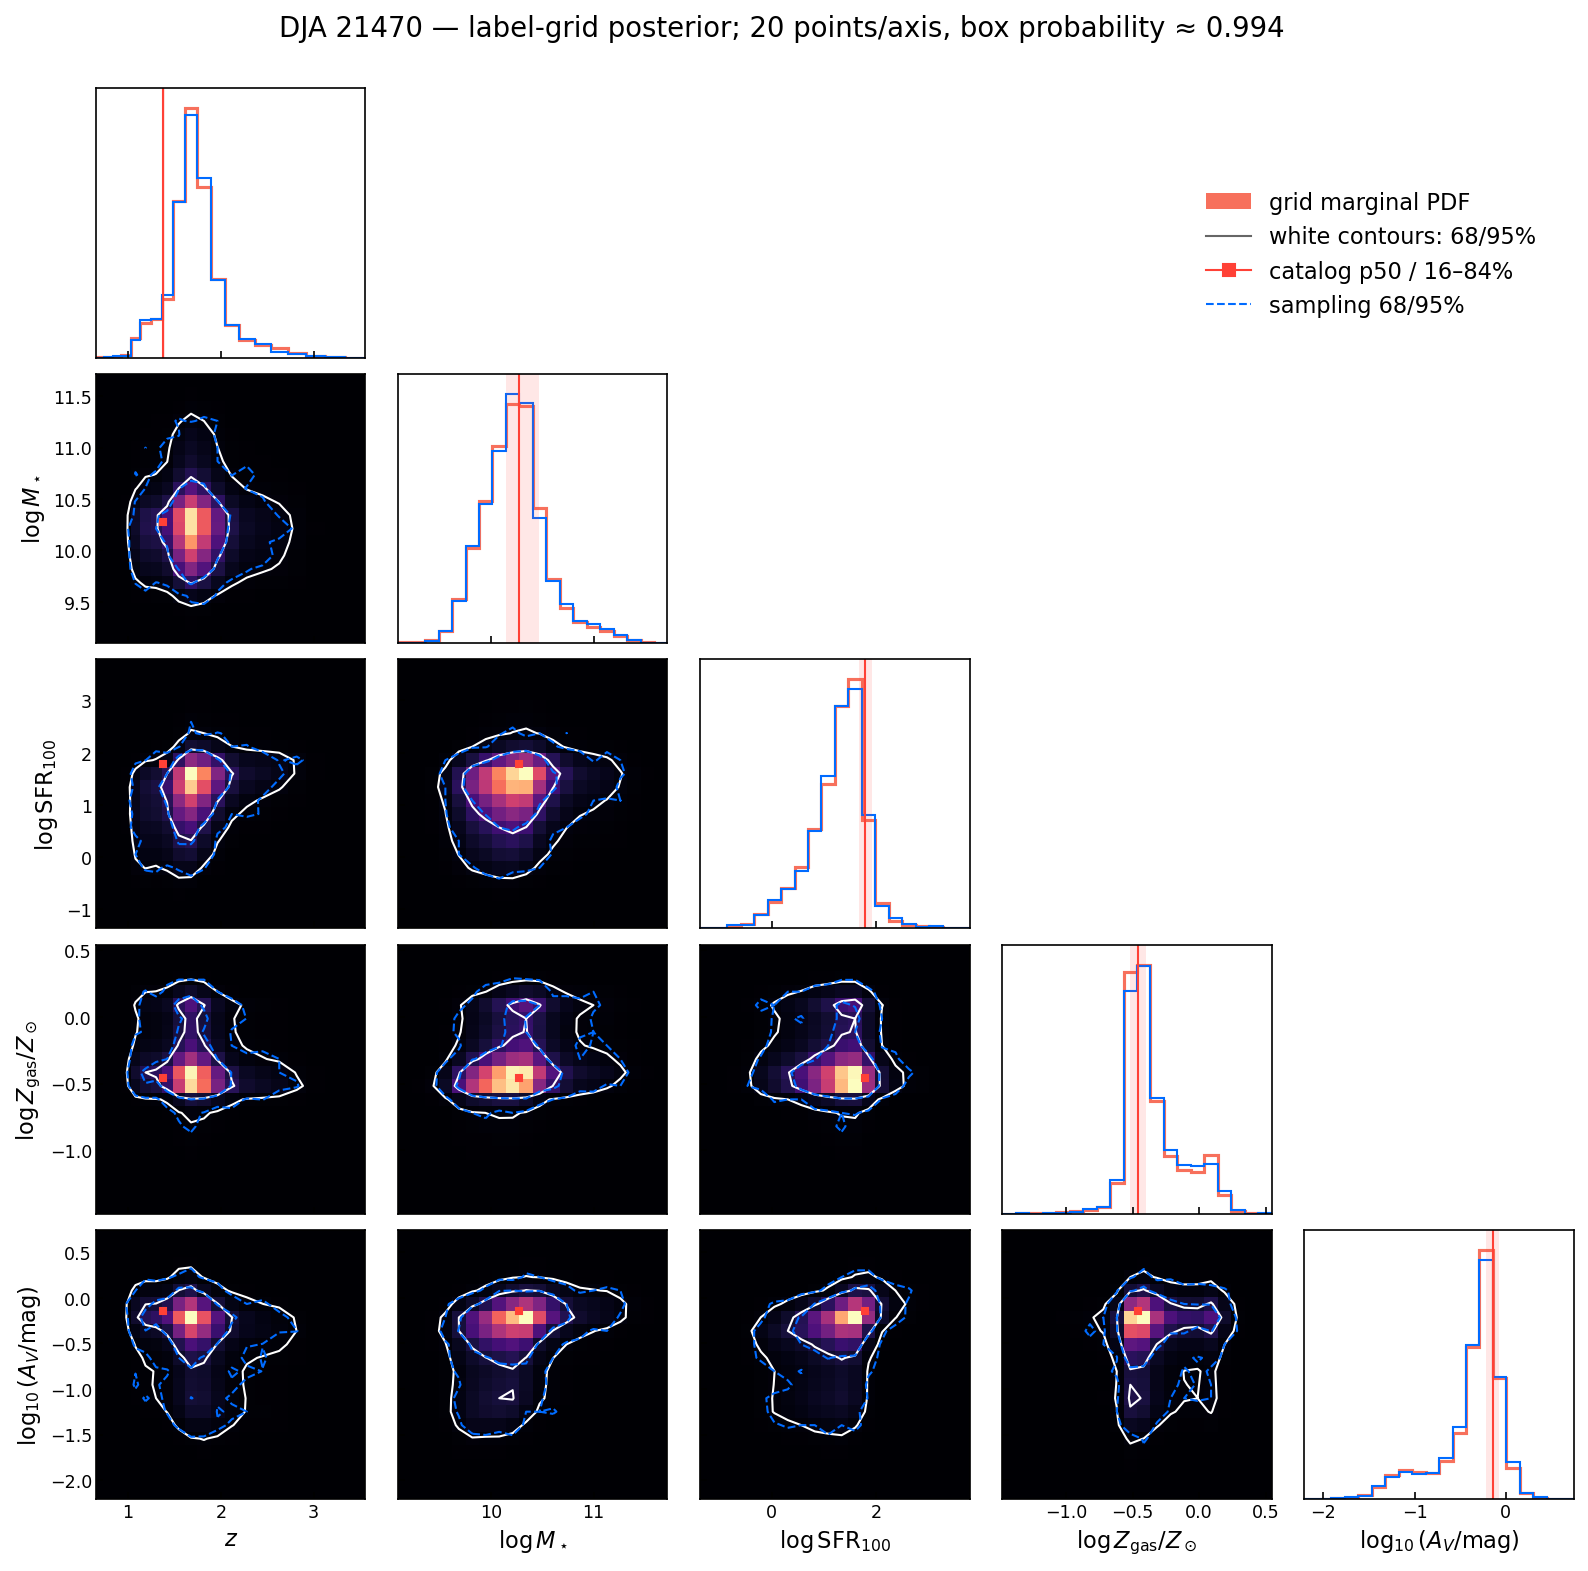

In [30]:
# 7. Grid marginal PDFs (cmap) + 68/95% contours; original sampling in blue.
# This cell only uses the computed grid. It does not reevaluate the flow.
GRID_CMAP = "magma"
OVERLAY_SAMPLES = True

k = grid_posterior["k"]
grid_mass = grid_posterior["mass"]
grid_edges = [e.copy() for e in grid_posterior["edges"]]
grid_centers = [c.copy() for c in grid_posterior["centers"]]
for d, name in enumerate(names):
    if name == "log1pz":
        grid_edges[d] = 10 ** grid_edges[d] - 1
        grid_centers[d] = 10 ** grid_centers[d] - 1
# Display-bin widths account for the log10(1+z) -> z density transformation.
grid_widths = [np.diff(e) for e in grid_edges]

# Both methods are compared within the SAME full 5D box.
in_box = np.ones(len(post_model), dtype=bool)
for d, edges in enumerate(grid_posterior["edges"]):
    in_box &= (post_model[:, k, d] >= edges[0]) & (post_model[:, k, d] <= edges[-1])
comparison_samples = post[in_box, k]


def grid_contour_levels(pdf, probability_mass, probs=(0.95, 0.68)):
    order = np.argsort(pdf.ravel())[::-1]
    cumulative = np.cumsum(probability_mass.ravel()[order])
    cumulative /= cumulative[-1]
    return np.unique([pdf.ravel()[order[min(np.searchsorted(cumulative, p), len(order) - 1)]]
                      for p in probs])


# Cache small 1D/2D marginals so drawing the comparison does not rescan the 5D grid.
grid_marginals, sample_marginals = {}, {}
for i in range(D):
    grid_marginals[i, i] = grid_mass.sum(axis=tuple(d for d in range(D) if d != i))
    counts, _ = np.histogram(comparison_samples[:, i], bins=grid_edges[i])
    sample_marginals[i, i] = counts / counts.sum()
    for j in range(i):
        grid_marginals[i, j] = grid_mass.sum(axis=tuple(d for d in range(D) if d not in (i, j))).T
        counts, _, _ = np.histogram2d(comparison_samples[:, j], comparison_samples[:, i],
                                      bins=[grid_edges[j], grid_edges[i]])
        sample_marginals[i, j] = counts.T / counts.sum()


def draw_posterior_corner(axes, method="grid", overlay_samples=False):
    marginals = grid_marginals if method == "grid" else sample_marginals
    line_color = plt.get_cmap(GRID_CMAP)(0.7) if method == "grid" else C_IMAGE
    for i in range(D):
        for j in range(D):
            ax = axes[i, j]
            ax.set_box_aspect(1)
            if j > i:
                ax.axis("off")
                continue
            if i == j:
                pdf = marginals[i, i] / grid_widths[i]
                ax.stairs(pdf, grid_edges[i], color=line_color, lw=1.5)
                if overlay_samples:
                    ax.stairs(sample_marginals[i, i] / grid_widths[i], grid_edges[i],
                              color=C_IMAGE, lw=1)
                ax.axvspan(yt16[k, i], yt84[k, i], color=C_RED_BRIGHT, alpha=0.12, lw=0)
                ax.axvline(yt[k, i], color=C_RED_BRIGHT, lw=1)
                # Identical diagonal density scale for both methods.
                peak = max((grid_marginals[i, i] / grid_widths[i]).max(),
                           (sample_marginals[i, i] / grid_widths[i]).max())
                ax.set_ylim(0, 1.08 * peak)
                ax.set_yticks([])
            else:
                probability_mass = marginals[i, j]
                pdf = probability_mass / np.outer(grid_widths[i], grid_widths[j])
                # Shared color scale for the corresponding pair in both corner plots.
                vmax = max((grid_marginals[i, j] / np.outer(grid_widths[i], grid_widths[j])).max(),
                           (sample_marginals[i, j] / np.outer(grid_widths[i], grid_widths[j])).max())
                ax.pcolormesh(grid_edges[j], grid_edges[i], pdf, cmap=GRID_CMAP,
                              vmin=0, vmax=vmax, shading="flat", rasterized=True)
                levels = grid_contour_levels(pdf, probability_mass)
                ax.contour(grid_centers[j], grid_centers[i], pdf, levels=levels,
                           colors="white", linewidths=1)
                if overlay_samples:
                    sample_mass = sample_marginals[i, j]
                    sample_pdf = sample_mass / np.outer(grid_widths[i], grid_widths[j])
                    ax.contour(grid_centers[j], grid_centers[i], sample_pdf,
                               levels=grid_contour_levels(sample_pdf, sample_mass),
                               colors=C_IMAGE, linestyles="--", linewidths=1)
                ax.plot(yt[k, j], yt[k, i], "s", color=C_RED_BRIGHT, ms=3)
                ax.set_ylim(grid_edges[i][0], grid_edges[i][-1])
            ax.set_xlim(grid_edges[j][0], grid_edges[j][-1])
            ax.tick_params(direction="in", labelsize=fs(7), pad=2)
            if i < D - 1:
                ax.tick_params(labelbottom=False)
            else:
                ax.set_xlabel(LABELS[j], fontsize=fs(9), labelpad=3)
            if j > 0 or i == 0:
                ax.tick_params(labelleft=False)
            else:
                ax.set_ylabel(LABELS[i], fontsize=fs(9), labelpad=3)


# Manual spacing + square panels. A long axes legend must not enter tight_layout.
fig, axes = plt.subplots(D, D, figsize=(2.2 * D, 2.2 * D), squeeze=False, layout="none",
                         gridspec_kw={"hspace": 0.06, "wspace": 0.06})
fig.subplots_adjust(left=0.08, right=0.985, bottom=0.075, top=0.93)
draw_posterior_corner(axes, method="grid", overlay_samples=OVERLAY_SAMPLES)
handles = [Patch(facecolor=plt.get_cmap(GRID_CMAP)(0.7), label="grid marginal PDF"),
           Line2D([], [], color="0.4", lw=1, label="white contours: 68/95%"),
           Line2D([], [], color=C_RED_BRIGHT, marker="s", lw=1, label="catalog p50 / 16–84%")]
if OVERLAY_SAMPLES:
    handles.append(Line2D([], [], color=C_IMAGE, ls="--", lw=1, label="sampling 68/95%"))
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.97, 0.88),
           frameon=False, fontsize=fs(9))
fig.suptitle(f"DJA {did_all[k]} — label-grid posterior; "
             f"{grid_posterior['n_grid']} points/axis, box probability ≈ {grid_posterior['box_mass']:.3f}",
             y=0.975, fontsize=fs(11))
plt.show()


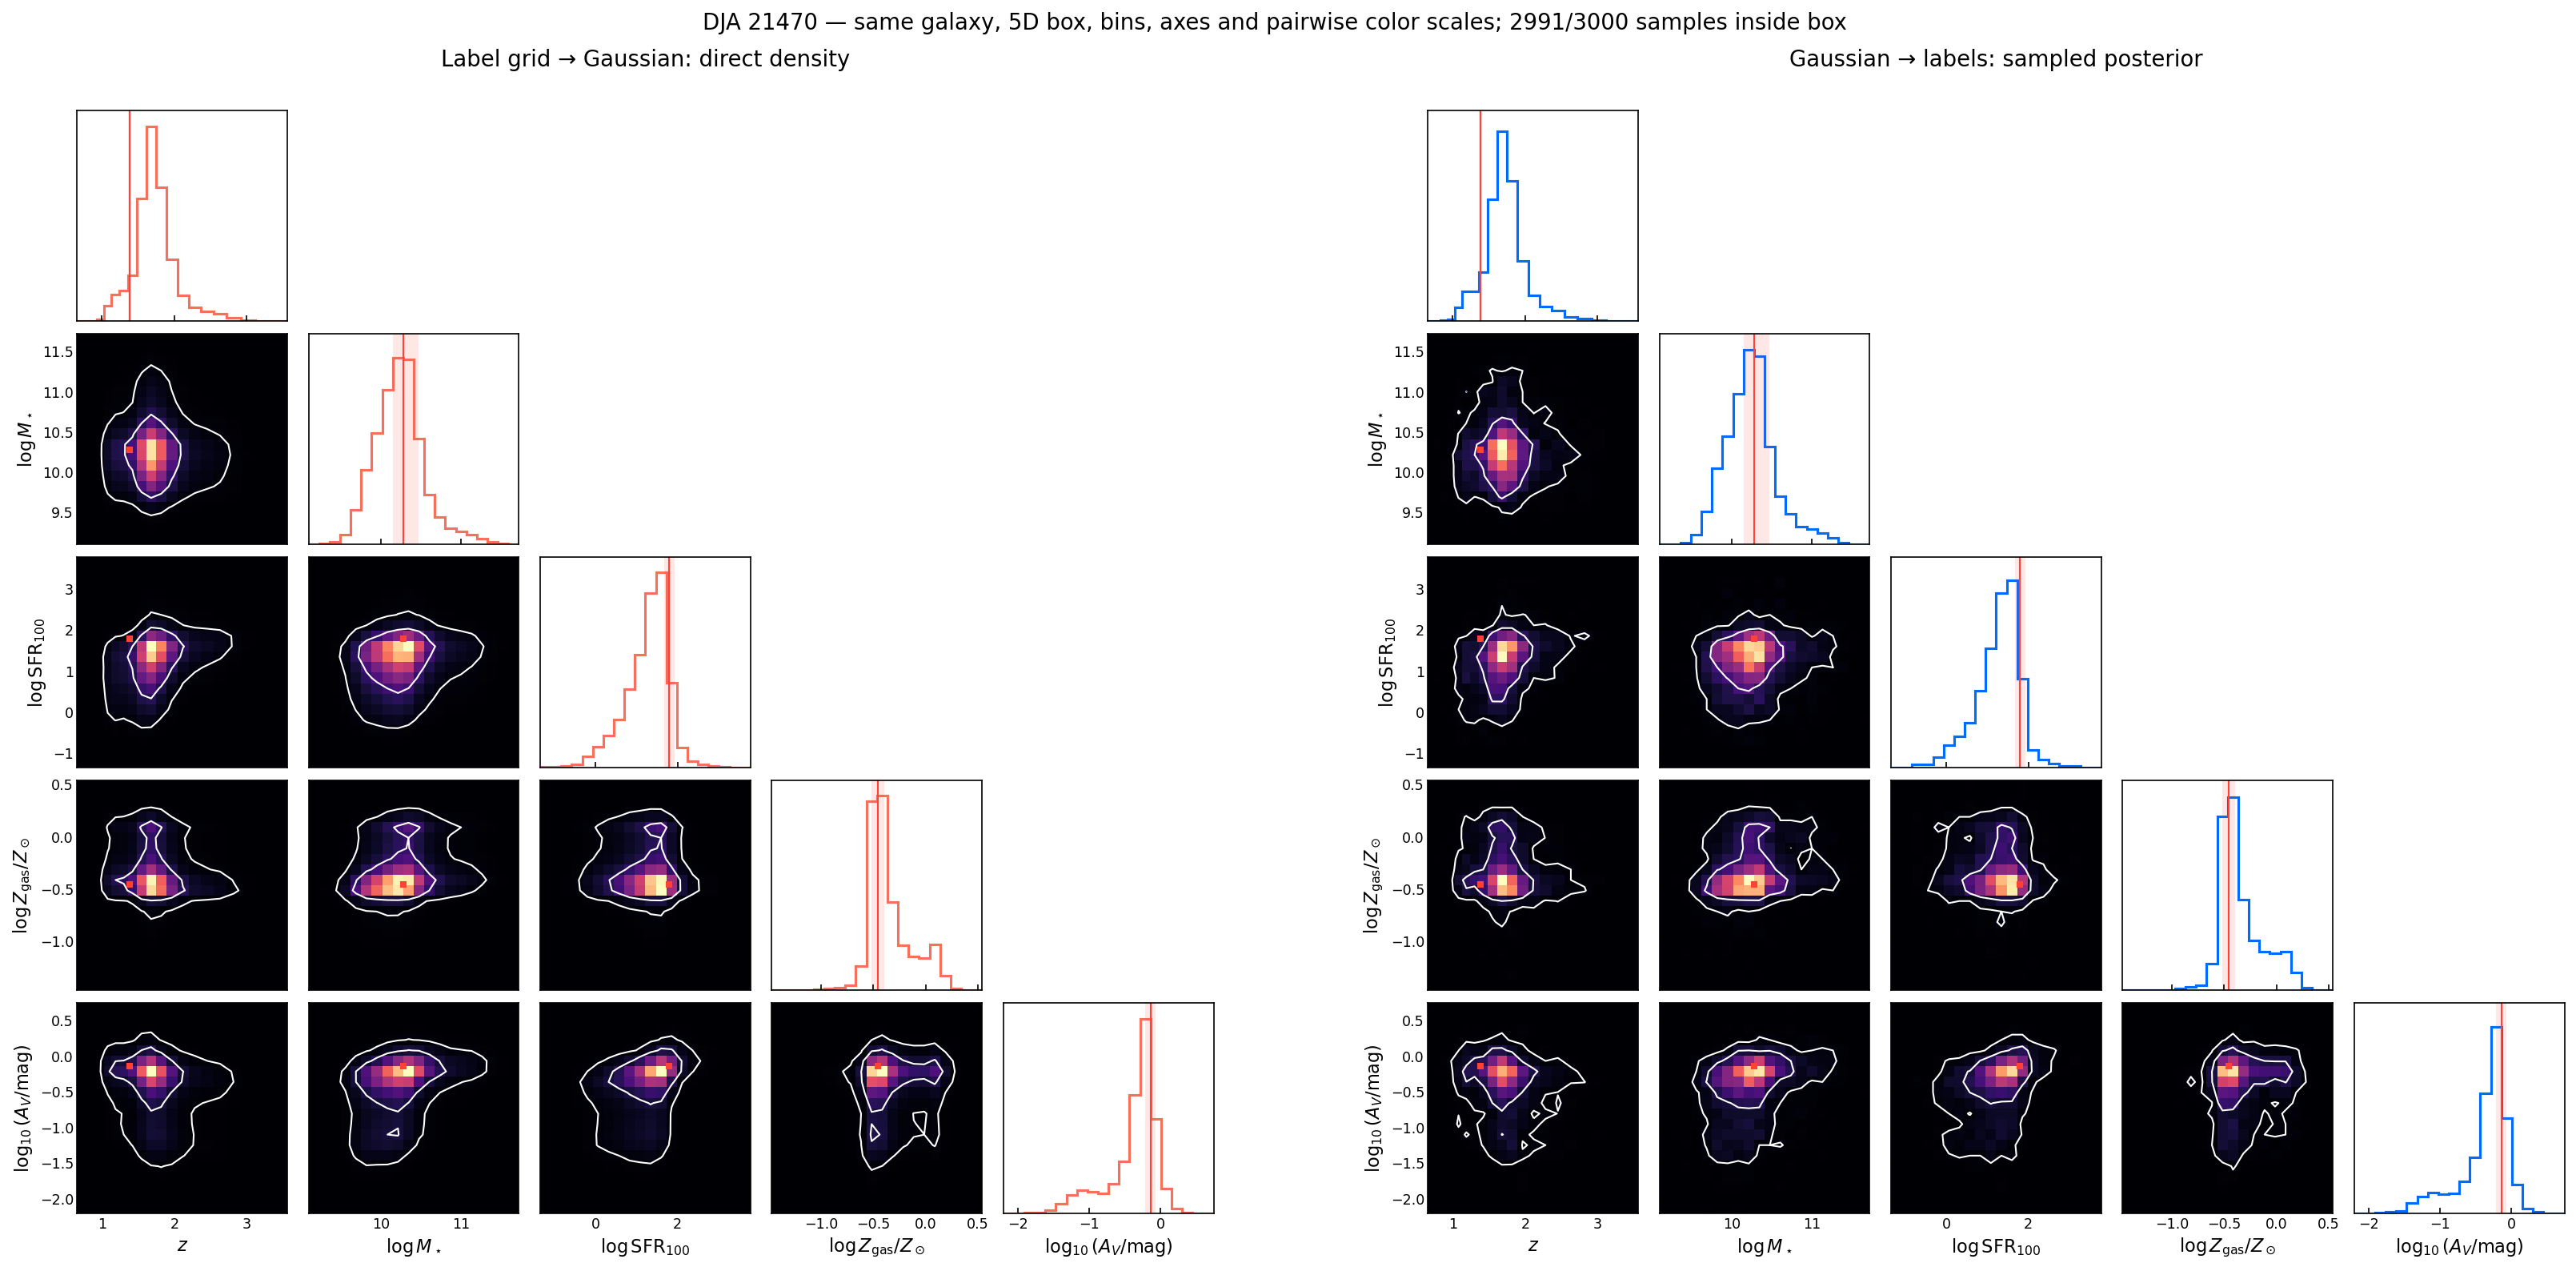

In [31]:
# 8. Side-by-side comparison. Reuses the grid and samples; no new inference.
fig_compare = plt.figure(figsize=(4.4 * D, 2.2 * D), layout="none")
outer = fig_compare.add_gridspec(1, 2, left=0.045, right=0.99, bottom=0.075, top=0.91, wspace=0.18)
comparison_axes = []
for side, (method, title) in enumerate([
    ("grid", "Label grid → Gaussian: direct density"),
    ("sample", "Gaussian → labels: sampled posterior"),
]):
    panels = outer[side].subgridspec(D, D, hspace=0.06, wspace=0.06)
    corner_axes = np.array([[fig_compare.add_subplot(panels[i, j]) for j in range(D)] for i in range(D)])
    draw_posterior_corner(corner_axes, method=method)
    comparison_axes.append(corner_axes)
    position = outer[side].get_position(fig_compare)
    fig_compare.text((position.x0 + position.x1) / 2, 0.94, title,
                     ha="center", va="bottom", fontsize=fs(11))
fig_compare.suptitle(f"DJA {did_all[k]} — same galaxy, 5D box, bins, axes and pairwise color scales; "
                     f"{len(comparison_samples)}/{len(post_model)} samples inside box",
                     y=0.985, fontsize=fs(11))
plt.show()
